# Credit Card Fraud Detection — Deep Exploratory Data Analysis

**Machine Learning project | EDA only: no models fitted**

**Dataset:** ULB / Worldline credit-card transactions, September 2013. https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud ; preserved at https://zenodo.org/records/7395559

**Scope:** Inspect all observations; review schema, missingness, duplicates and anomalies; explain display-only transformations; quantify severe class imbalance, amount patterns, relative-time behavior, and anonymous PCA associations. Nine figures in total. The data contain no date, location, customer or merchant identifiers.

## Dataset acquisition, reproducibility and data dictionary

The original dataset is 150.8 MB. Place creditcard.csv beside this notebook, or download from Zenodo. A shortened sample is not accepted. There are 31 columns: Time (seconds elapsed since the first observation, not local clock time), Amount (currency unspecified), anonymized principal components V1–V28, and Class (0 nonfraud, 1 fraud). Original features of V1–V28 are not known.

The original data are unchanged. No training, fitted preprocessing or class resampling occurs.

In [1]:
from pathlib import Path
import urllib.request, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from scipy.stats import norm
sns.set_theme(style='whitegrid',palette='Set2')
plt.rcParams.update({'figure.figsize':(11,5),'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
color={0:'#277da1',1:'#e76f51'}
p=Path('creditcard.csv')
if not p.exists():
 for u in ['https://huggingface.co/datasets/David-Egea/Creditcard-fraud-detection/resolve/main/creditcard.csv?download=true','https://huggingface.co/datasets/JEFFREY-VERDIERE/Creditcard/resolve/main/creditcard.csv?download=true','https://zenodo.org/records/7395559/files/creditcard.csv?download=1','https://zenodo.org/api/records/7395559/files/creditcard.csv/content']:
  try:
   req=urllib.request.Request(u,headers={'User-Agent':'Mozilla/5.0'})
   with urllib.request.urlopen(req,timeout=180) as f, open('creditcard.tmp','wb') as o:
    while True:
     b=f.read(1024*1024)
     if not b:break
     o.write(b)
   Path('creditcard.tmp').replace(p)
   break
  except Exception as e:
   print('Download source failed:',str(e)[:140]);Path('creditcard.tmp').unlink(missing_ok=True)
if not p.exists():raise FileNotFoundError('Download the original creditcard.csv dataset manually from Kaggle.')
df=pd.read_csv(p)
assert df.shape==(284807,31),'Must use the COMPLETE original dataset'
assert set(df.columns)==set(['Time','Amount','Class']+[f'V{i}' for i in range(1,29)])
assert set(df.Class.unique())=={0,1}
print('FULL dataset loaded:',df.shape)
display(df.head())

FULL dataset loaded: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 1. Data-quality audit and transformation policy

Audit missing cells, types, infinite values, negative amounts, constants, exact duplicates and amount zeros. Exact matching rows are reported, not automatically removed: without a transaction ID one cannot establish that two identical records refer to the same underlying event. Imputation is only appropriate if null values are found; original data have no nulls. The transformed logarithm of amount and elapsed-hour grouping are exclusively for descriptive EDA, without overwriting source columns.

In [2]:
profile=pd.DataFrame({'dtype':df.dtypes.astype(str),'missing':df.isna().sum(),'missing_pct':df.isna().mean()*100,'unique':df.nunique()})
display(profile)
print('Exact duplicate rows retained:',df.duplicated().sum(),'| Zero amounts:',(df.Amount==0).sum())
print('Infinity entries:',np.isinf(df.to_numpy()).sum(),'| Negative amounts:',(df.Amount<0).sum())
assert df.isna().sum().sum()==0 and not np.isinf(df.to_numpy()).any() and (df.Amount>=0).all()
display(df[['Time','Amount','V1','V2','Class']].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T.round(3))
eda=df.copy();eda['elapsed_hour']=(df.Time//3600).astype(int);eda['log_amount']=np.log1p(df.Amount)
counts=df.Class.value_counts().sort_index();rate=counts[1]/len(df)
print('Fraud:',counts[1],'of',len(df),'| rate:',f'{rate:.4%}','| elapsed hours:',round(df.Time.max()/3600,2))

,dtype,missing,missing_pct,unique
Time,float64,0,0.0,124592
V1,float64,0,0.0,275663
V2,float64,0,0.0,275663
V3,float64,0,0.0,275663
V4,float64,0,0.0,275663
V5,float64,0,0.0,275663
V6,float64,0,0.0,275663
V7,float64,0,0.0,275663
V8,float64,0,0.0,275663
V9,float64,0,0.0,275663


Exact duplicate rows retained: 1081 | Zero amounts: 1825
Infinity entries: 0 | Negative amounts: 0


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Time,284807.0,94813.860,47488.146,0.000,2422.000,25297.600,54201.500,84692.000,139320.500,164143.400,170560.940,172792.000
Amount,284807.0,88.350,250.120,0.000,0.120,0.920,5.600,22.000,77.165,365.000,1017.970,25691.160
V1,284807.0,0.000,1.959,-56.408,-6.563,-2.899,-0.920,0.018,1.316,2.081,2.237,2.455
V2,284807.0,0.000,1.651,-72.716,-4.960,-1.972,-0.599,0.065,0.804,1.809,3.802,22.058
Class,284807.0,0.002,0.042,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000


Fraud: 492 of 284807 | rate: 0.1727% | elapsed hours: 48.0


## 2. Figure 1 — Class imbalance

The logarithmic side view reveals the rare fraud group. The absolute count must accompany any rate. High predictive accuracy would be misleading on this imbalanced dataset, but no predictive algorithm is fit in this notebook.

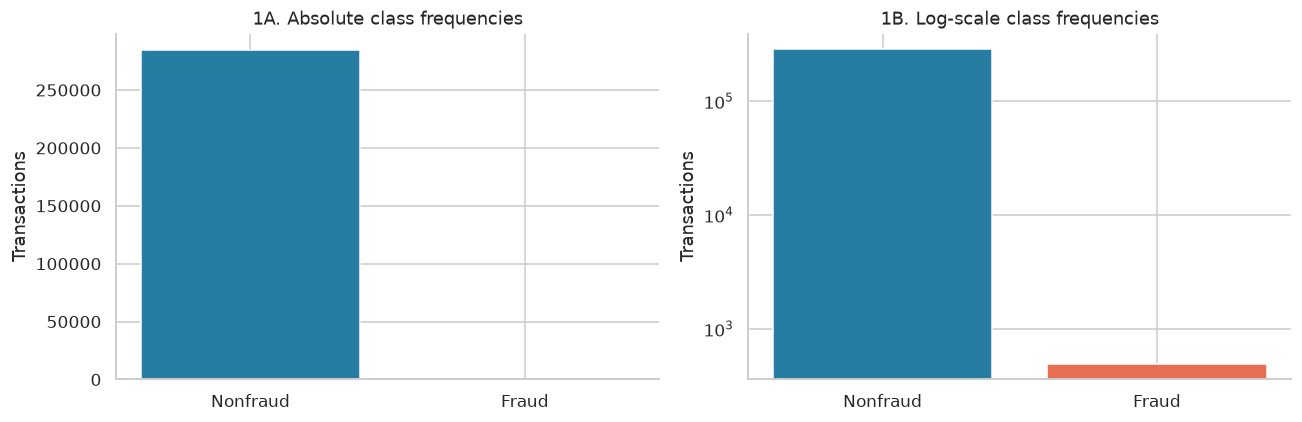

In [3]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
for a in ax:a.bar(['Nonfraud','Fraud'],counts.values,color=[color[0],color[1]]);a.set_ylabel('Transactions')
ax[0].set_title('1A. Absolute class frequencies');ax[1].set_yscale('log');ax[1].set_title('1B. Log-scale class frequencies')
plt.tight_layout();plt.show()

## 3. Figures 2–3 — Transaction amount

Amount is often long-tailed; median and high percentiles are more informative than the mean alone. Plot the class-conditional density on a log(1+Amount) display scale, typical values with outlier markers suppressed only visually, and upper percentiles on a log axis. Neither nulls nor outliers are discarded.

Class,0,1
count,284315.000,492.000
mean,88.291,122.211
std,250.105,256.683
min,0.000,0.000
10%,1.000,0.760
25%,5.650,1.000
50%,22.000,9.250
75%,77.050,105.890
90%,202.724,346.746
95%,364.409,640.905


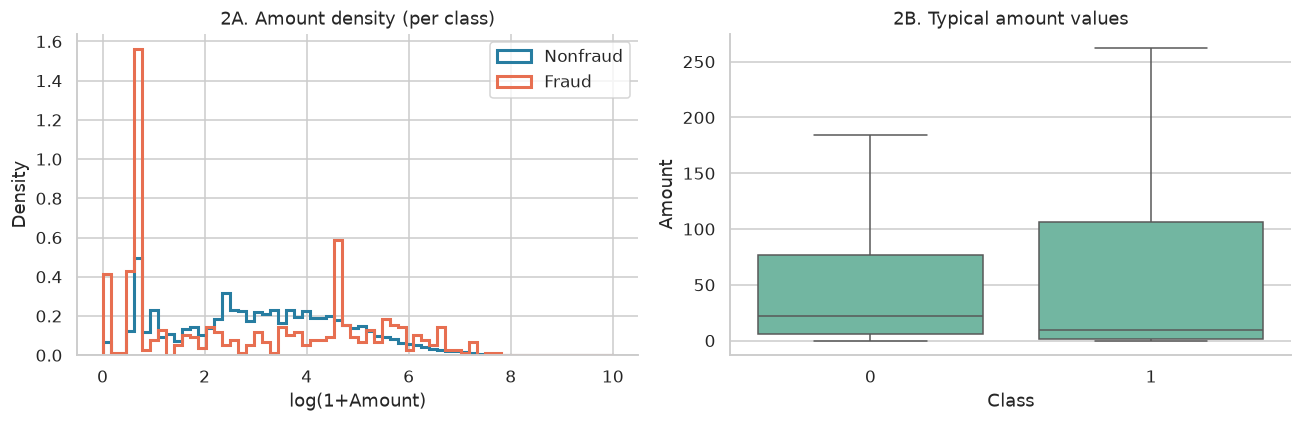

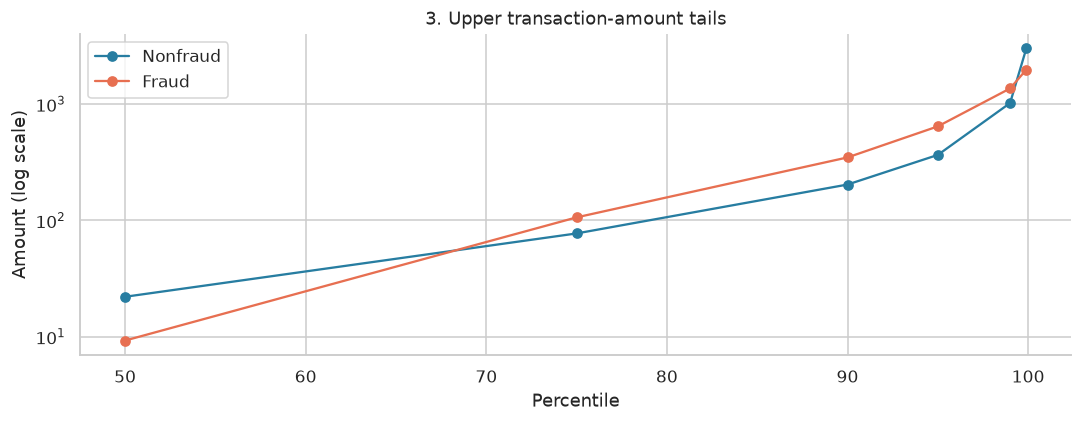

In [4]:
display(df.groupby('Class').Amount.describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]).T.round(3))
fig,ax=plt.subplots(1,2,figsize=(12,4))
for cl,label in [(0,'Nonfraud'),(1,'Fraud')]:ax[0].hist(eda.loc[eda.Class==cl,'log_amount'],bins=np.linspace(0,10,65),density=True,histtype='step',lw=2,color=color[cl],label=label)
ax[0].legend();ax[0].set(title='2A. Amount density (per class)',xlabel='log(1+Amount)',ylabel='Density')
sns.boxplot(data=eda,x='Class',y='Amount',showfliers=False,ax=ax[1]);ax[1].set_title('2B. Typical amount values');plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(10,4));qs=[.5,.75,.9,.95,.99,.999]
for cl,label in [(0,'Nonfraud'),(1,'Fraud')]:ax.plot([100*q for q in qs],[df.loc[df.Class==cl,'Amount'].quantile(q) for q in qs],marker='o',color=color[cl],label=label)
ax.set_yscale('log');ax.set(xlabel='Percentile',ylabel='Amount (log scale)',title='3. Upper transaction-amount tails');ax.legend();plt.tight_layout();plt.show()

## 4. Figure 4 — Relative-time activity

Time is seconds since the first recorded transaction. The elapsed-hour axis must NOT be interpreted as local hour of day. Counts reflect volume, not individual fraud probabilities.

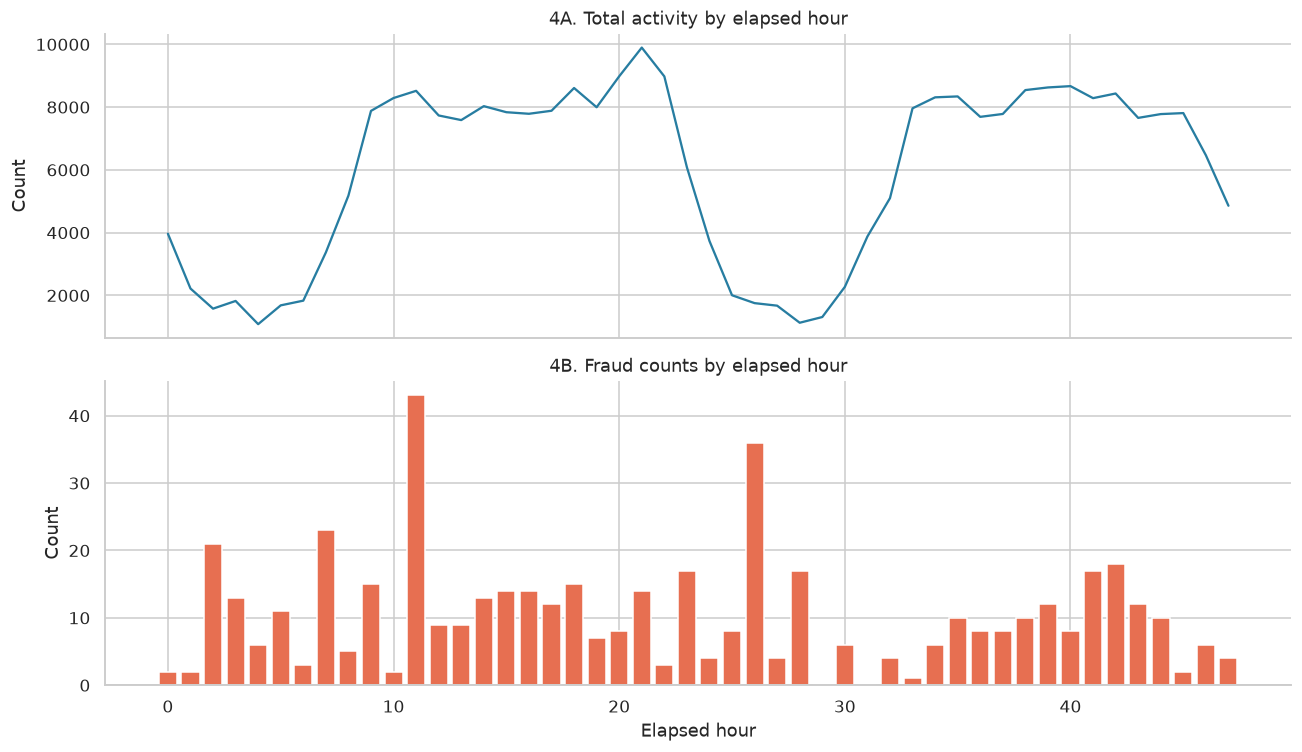

In [5]:
hour=eda.groupby(['elapsed_hour','Class']).size().unstack(fill_value=0).reindex(columns=[0,1],fill_value=0);hour['total']=hour[0]+hour[1];hour['rate']=hour[1]/hour.total
fig,ax=plt.subplots(2,1,figsize=(12,7),sharex=True)
ax[0].plot(hour.index,hour.total,color=color[0]);ax[0].set(title='4A. Total activity by elapsed hour',ylabel='Count')
ax[1].bar(hour.index,hour[1],color=color[1]);ax[1].set(title='4B. Fraud counts by elapsed hour',xlabel='Elapsed hour',ylabel='Count')
plt.tight_layout();plt.show()

## 5. Figure 5 — Fraud rates by elapsed hour, with uncertainty

Wilson 95% binomial score intervals illustrate how much a measured hourly fraction can vary with the denominator. No time-of-day causal inference is claimed, and these intervals are not classifier confidence estimates.

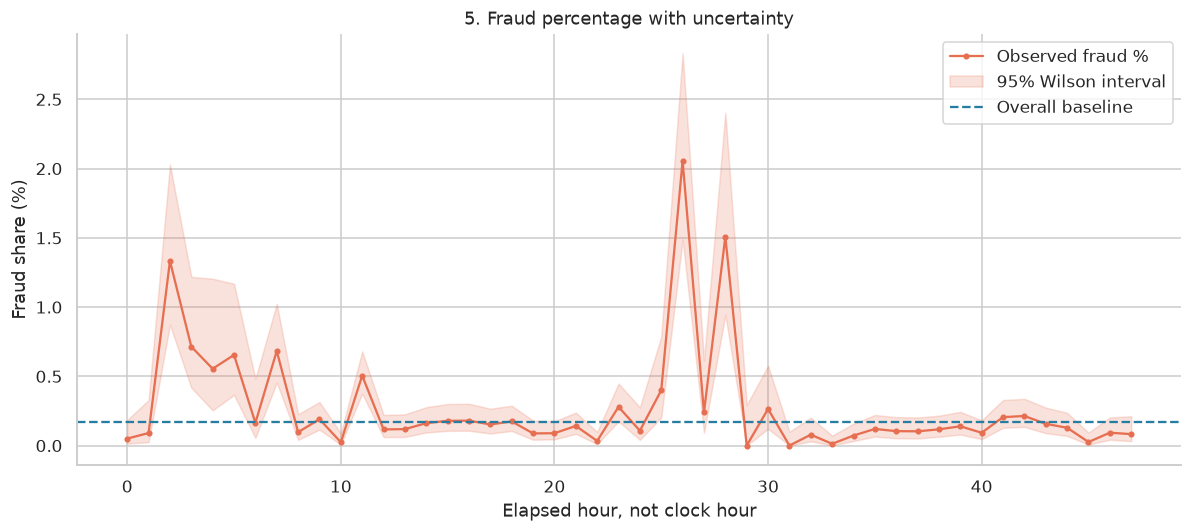

In [6]:
z=norm.ppf(.975);nn=hour.total.to_numpy(dtype=float);q=hour.rate.to_numpy();den=1+z*z/nn;mid=(q+z*z/(2*nn))/den;err=z/den*np.sqrt(q*(1-q)/nn+z*z/(4*nn*nn))
fig,ax=plt.subplots();ax.plot(hour.index,100*q,color=color[1],marker='o',markersize=3,label='Observed fraud %');ax.fill_between(hour.index,100*(mid-err),100*(mid+err),color=color[1],alpha=.2,label='95% Wilson interval')
ax.axhline(100*rate,ls='--',color=color[0],label='Overall baseline');ax.set(title='5. Fraud percentage with uncertainty',xlabel='Elapsed hour, not clock hour',ylabel='Fraud share (%)');ax.legend();plt.tight_layout();plt.show()

## 6. Figure 6 — Anonymized PCA component distributions

Compute a descriptive standardized difference in group means for V1–V28. This is a summary statistic, not feature selection or model training. Display six high-contrast dimensions with no speculative domain labels.

,Standardized difference
V14,-2.259
V4,2.013
V11,1.882
V12,-1.867
V10,-1.606
V16,-1.482
V3,-1.373
V17,-1.347
V9,-1.340
V2,1.118


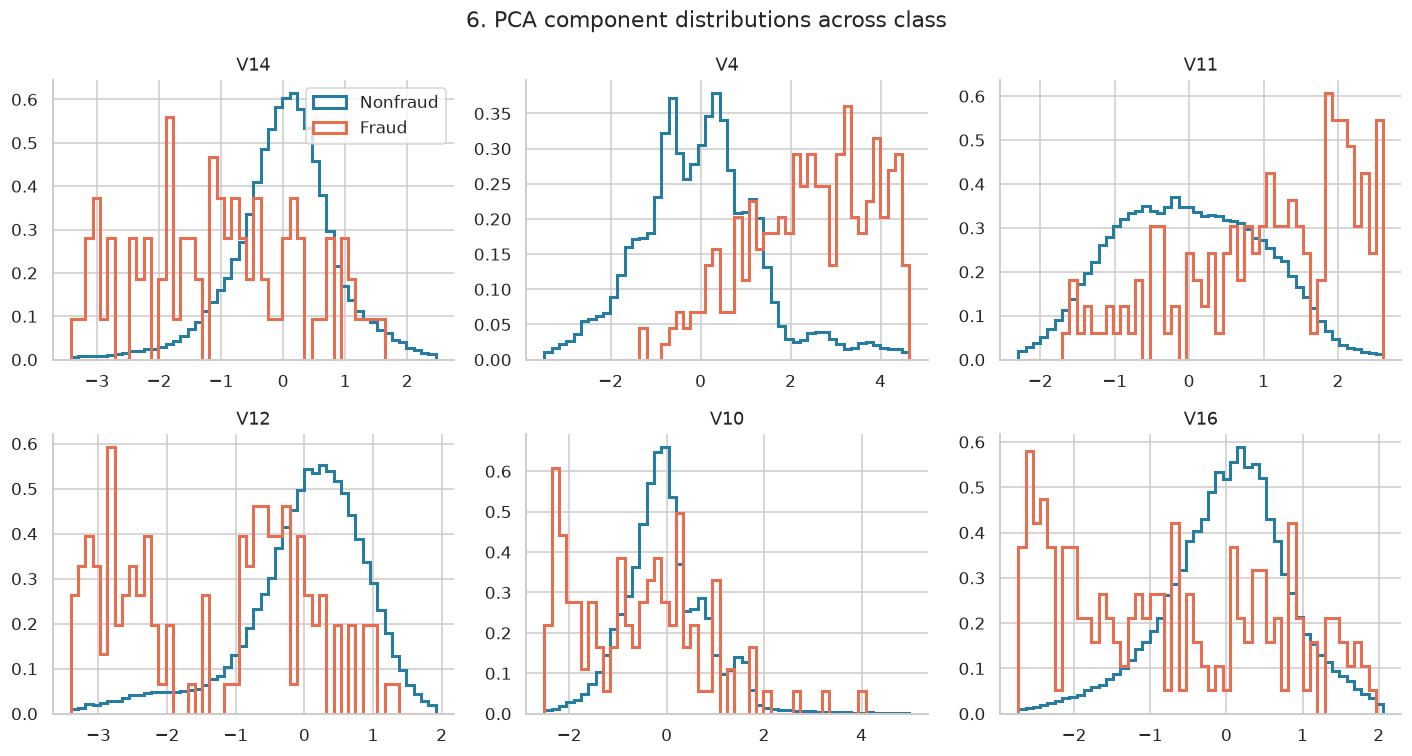

In [7]:
V=[f'V{i}' for i in range(1,29)];g=df.groupby('Class')[V];means=g.mean();std=g.std();contrast=((means.loc[1]-means.loc[0])/np.sqrt((std.loc[0]**2+std.loc[1]**2)/2)).sort_values(key=np.abs,ascending=False)
display(contrast.head(12).round(3).to_frame('Standardized difference'))
fig,axes=plt.subplots(2,3,figsize=(13,7))
for a,v in zip(axes.flat,contrast.index[:6]):
 lo,hi=df[v].quantile([.005,.995]);bins=np.linspace(lo,hi,51)
 for cl,label in [(0,'Nonfraud'),(1,'Fraud')]:a.hist(df.loc[df.Class==cl,v],bins=bins,density=True,histtype='step',lw=2,color=color[cl],label=label)
 a.set_title(v)
axes[0,0].legend();fig.suptitle('6. PCA component distributions across class');plt.tight_layout();plt.show()

## 7. Figure 7 — Numeric correlation

Pearson correlation is descriptive, not causal and not an estimate of classifier performance. The anonymized dimensions were created by PCA and cannot be assigned business meanings.

,Pearson r
V17,-0.3265
V14,-0.3025
V12,-0.2606
V10,-0.2169
V16,-0.1965
V3,-0.1930
V7,-0.1873
V11,0.1549
V4,0.1334
V18,-0.1115


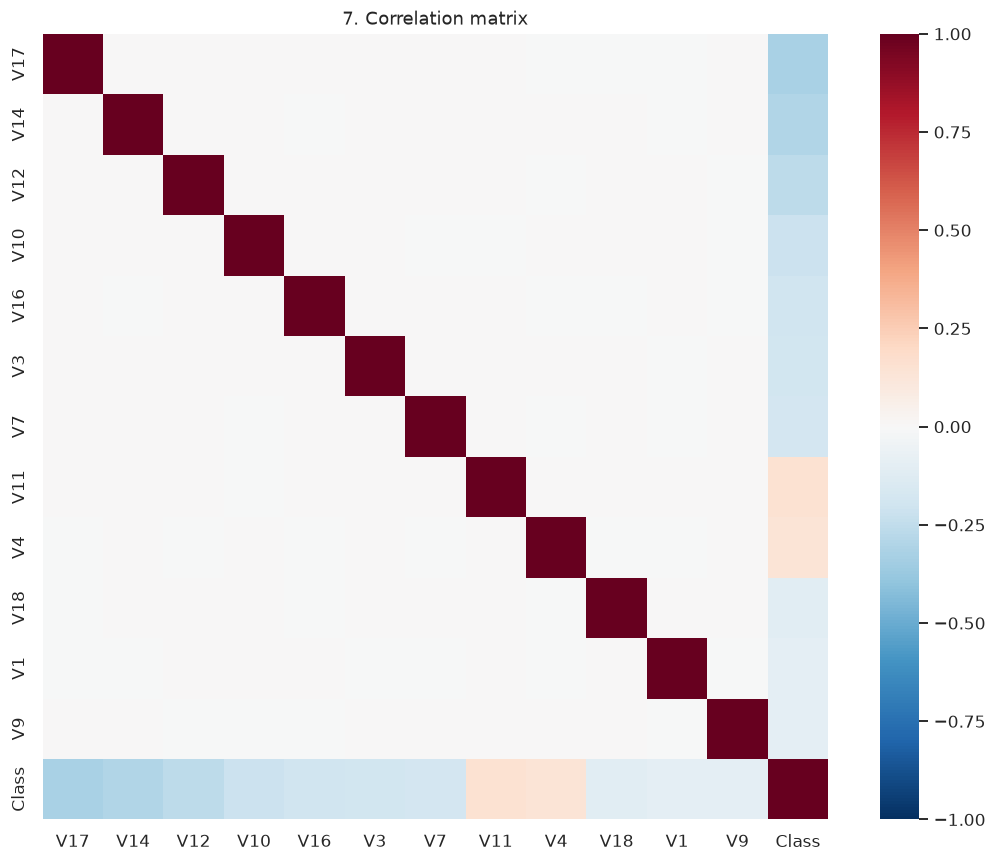

In [8]:
corr=df[V+['Time','Amount','Class']].corr();top=corr.Class.drop('Class').abs().nlargest(12).index.tolist()
display(corr.Class.loc[top].round(4).to_frame('Pearson r'))
fig,ax=plt.subplots(figsize=(10,8));sns.heatmap(corr.loc[top+['Class'],top+['Class']],cmap='RdBu_r',center=0,vmin=-1,vmax=1,square=True,ax=ax);ax.set_title('7. Correlation matrix');plt.tight_layout();plt.show()

## 8. Figure 8 — Amount-rank deciles

Divide the full dataset into approximately equal-size rank deciles to avoid broken quantile boundaries at tied amounts. Each fraud percentage uses the original full-bin transaction denominator, not an undersampled subset.

,n,fraud,median_amount,fraud_pct
amount_decile,,,,
1,28480,175,0.92,0.614
2,28481,33,1.98,0.116
3,28481,36,5.60,0.126
4,28480,13,10.00,0.046
5,28481,14,16.99,0.049
6,28481,17,29.00,0.060
7,28480,24,46.71,0.084
8,28481,50,77.16,0.176
9,28481,45,140.00,0.158


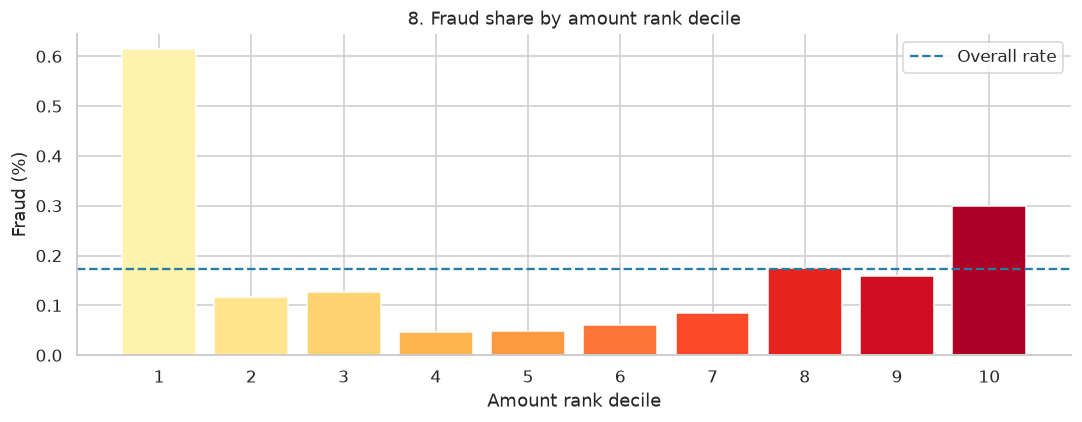

In [9]:
eda['amount_decile']=np.minimum(np.ceil(df.Amount.rank(method='first',pct=True)*10).astype(int),10)
dec=eda.groupby('amount_decile').agg(n=('Class','size'),fraud=('Class','sum'),median_amount=('Amount','median'));dec['fraud_pct']=100*dec.fraud/dec.n;display(dec.round(3))
fig,ax=plt.subplots(figsize=(10,4));ax.bar(dec.index.astype(str),dec.fraud_pct,color=sns.color_palette('YlOrRd',10));ax.axhline(100*rate,ls='--',color=color[0],label='Overall rate');ax.set(title='8. Fraud share by amount rank decile',xlabel='Amount rank decile',ylabel='Fraud (%)');ax.legend();plt.tight_layout();plt.show()

## 9. Figure 9 — V1/V2 descriptive scatter

These are two pre-existing components, not a newly fitted projection. Plot all fraud records and 8,000 randomly sampled nonfraud observations for illustrative readability only. Rates and statistics above always use all 284,807 transactions.

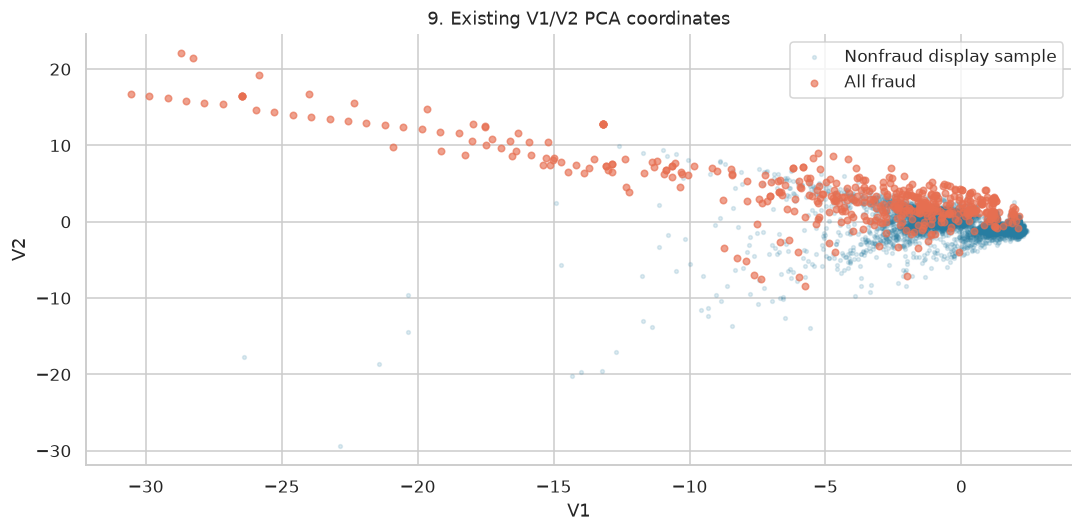

In [10]:
legit=df[df.Class==0].sample(n=8000,random_state=42);fraud=df[df.Class==1];fig,ax=plt.subplots(figsize=(10,5));ax.scatter(legit.V1,legit.V2,s=6,alpha=.15,color=color[0],label='Nonfraud display sample');ax.scatter(fraud.V1,fraud.V2,s=18,alpha=.65,color=color[1],label='All fraud')
ax.set(xlabel='V1',ylabel='V2',title='9. Existing V1/V2 PCA coordinates');ax.legend();plt.tight_layout();plt.show()

## 10. Integrity checks, interpretation and limitations

No imputation is needed when the original source has no missing data. Exact matching rows are retained because there are no unique transaction IDs. Zeros and extreme amounts are preserved because automatic outlier removal could obscure fraud. This dataset dates to September 2013, covers only two days, contains 492 labeled fraud events, and does not provide customer identity, merchant, location, original V1–V28 meaning or verifiable label provenance. Correlation and visualization are not causation or production validation. Future phases may consider class-weighted models and precision/recall, but absolutely none are implemented here.

**References:** ULB / Worldline dataset, https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud ; archival copy, https://zenodo.org/records/7395559 ; Wilson (1927), DOI 10.1080/01621459.1927.10502953.

In [11]:
assert counts.sum()==284807 and hour[1].sum()==counts[1] and dec.fraud.sum()==counts[1] and dec.n.sum()==284807
result=pd.Series({'Rows':len(df),'Columns':df.shape[1],'Fraud cases':counts[1],'Fraud percentage':round(rate*100,5),'Missing cells':df.isna().sum().sum(),'Duplicate matching rows (retained)':df.duplicated().sum(),'Zero amount records':(df.Amount==0).sum(),'Maximum amount':df.Amount.max(),'Elapsed duration (hours)':round(df.Time.max()/3600,2)})
display(result.to_frame('Measured value'));print('VALIDATED: full dataset, EDA only, nine figures.')

,Measured value
Rows,284807.00000
Columns,31.00000
Fraud cases,492.00000
Fraud percentage,0.17275
Missing cells,0.00000
Duplicate matching rows (retained),1081.00000
Zero amount records,1825.00000
Maximum amount,25691.16000
Elapsed duration (hours),48.00000


VALIDATED: full dataset, EDA only, nine figures.
